# 02. BdG matrix and exact diagonalization

Follow the four blocks of your active BdG matrix, explain its hole-basis signs, and check the eigensystem numerically.

**Read this notebook from top to bottom.** Each section explains one calculation before showing its code. All functions needed to run it are visible below; no earlier notebook is required.

**Source labels.** **Thesis** identifies the stated model in Aditya Banerjee's [2023 MSc thesis](https://drive.google.com/file/d/1d9WheYwEY23cPAlLxxVOUfQDr9jLdqb9/view). **Source translation** identifies the active Mathematica calculation at commit `d88d12c`. **Extension / algebra** identifies new Python implementation or explicit derivations. Numerical output is evidence only for the displayed parameters. No speculative physical identification is assumed.

**Units and conventions.** Choose one energy unit $E_0$ and lattice spacing $a$. Displayed energies mean $E/E_0$, coordinates mean $x/a$, and $k_x,k_y$ mean momentum times $a$. Thus $m,\lambda,\mu,\Delta,V,k_BT$ all have energy units before rescaling. Eigenvectors have norm one and dimensionless components. This is a nonrelativistic lattice calculation; no spacetime metric signature is used. Boundary conditions and the spin/Nambu basis are stated where each matrix is built.

**Code provenance.** The original files are [BdG topological.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/BdG%20topological.nb) and [added vortex.nb](https://github.com/adicos0/BdG-code-for-Topological-superconductor-with-vortex-/blob/d88d12cded1a954d53c2d36d515525c8100ded1c/added%20vortex.nb). See [SOURCE_MAP.md](../SOURCE_MAP.md) for exact cells, differences and references. Python functions are also collected in `python/bdg_models.py` for testing; the definitions here are identical.

## 1. Imports

In [1]:
import os
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "1")
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import eigh
from scipy.special import expit
plt.rcParams.update({"figure.figsize": (7, 4), "font.size": 11})

## 2. State the basis before writing the matrix

**Thesis:** §4.1 introduces BdG diagonalization; §4.4, Eqs. (4.10)–(4.12), gives pairing and spin blocks. **Algebra:** use an explicit canonical basis to remove sign ambiguity:
$$\Psi=(c_{1\uparrow},\ldots,c_{N\uparrow},c_{1\downarrow},\ldots,c_{N\downarrow},
 c_{1\uparrow}^\dagger,\ldots,c_{N\uparrow}^\dagger,c_{1\downarrow}^\dagger,\ldots,c_{N\downarrow}^\dagger)^T.$$
For an electron matrix $h=h^\dagger$, onsite spin-singlet pairing has
$$A=\begin{pmatrix}0&D_\Delta\\-D_\Delta&0\end{pmatrix},\qquad D_\Delta=\operatorname{diag}(\Delta_1,\ldots,\Delta_N).$$
The minus sign follows from fermion antisymmetry: $A^T=-A$. Then
$$H_{\rm BdG}=\begin{pmatrix}h&A\\A^\dagger&-h^*\end{pmatrix},\qquad
\widehat H=\tfrac12\Psi^\dagger H_{\rm BdG}\Psi+\text{constant}.$$
The factor $1/2$ compensates for Nambu doubling. $H$ has size $4N\times4N$ and each entry has energy units.

**Particle–hole check:** exchange electron and hole blocks with $\tau_x$ and complex conjugate with $K$. For $C=\tau_x K$,
$$\tau_x H^*\tau_x=\begin{pmatrix}-h&A^T\\A^*&h^*\end{pmatrix}
=\begin{pmatrix}-h&-A\\-A^\dagger&h^*\end{pmatrix}=-H.$$
Therefore an eigenpair $(E,w)$ has partner $(-E,Cw)$. This is a BdG redundancy and alone does not prove a topological state.

In [2]:
def coordinates(nx, ny):
    """Zero-based version of the source's x-outer, y-inner site order."""
    return np.array([(x, y) for x in range(nx) for y in range(ny)])

def legacy_blocks(nx, ny, m=0.5, lam=1.0):
    """Translate first Code cell: periodic dictionary hopping, not thesis Eq. 4.9.

    Require >=3 sites per direction so nearest-neighbour images are distinct.
    The source selects the first numeric periodic image, rather than summing
    duplicate images. These coincide for the supported sizes.
    """
    if min(nx, ny) < 3:
        raise ValueError('Legacy translation requires nx, ny >= 3.')
    xy = coordinates(nx, ny)
    n = nx * ny
    hopping = {(0, 0): 1.5*m}
    for dx, dy in [(1, 0), (-1, 0), (0, 1), (0, -1)]:
        hopping[dx, dy] = -m
    for dx in [-1, 1]:
        for dy in [-1, 1]:
            hopping[dx, dy] = m/4
    mixing = {d: lam*(1-1j) for d in [(1, 0), (-1, 0), (0, 1), (0, -1)]}

    def from_dictionary(entries):
        matrix = np.zeros((n, n), complex)
        for i, (x, y) in enumerate(xy):
            for (dx, dy), value in entries.items():
                j = ((x-dx) % nx)*ny + (y-dy) % ny
                matrix[i, j] = value
        return matrix.T  # source: tij[i][j] = tijmn[[j,i]]

    return from_dictionary(hopping), from_dictionary(mixing)

def legacy_bdg(h1, soc, mu, st):
    """Translate active hh1, hh2, SCs and H of Mathematica input cell 5."""
    n = len(st)
    diagonal = h1 + mu*np.eye(n)
    electron = np.block([[diagonal, soc], [soc.conj(), diagonal]])
    hole = np.block([[-diagonal.conj(), soc.conj()],
                     [soc, -diagonal.conj()]])
    zero = np.zeros((n, n), complex)
    pairing = np.block([[zero, np.diag(st)], [np.diag(st), zero]])
    return np.block([[electron, pairing], [pairing.conj(), hole]])

def canonical_bdg(electron, delta):
    """Standard spin-singlet BdG in (c_up,c_down,c_up†,c_down†)."""
    n = len(delta)
    zero = np.zeros((n, n), complex)
    pairing = np.block([[zero, np.diag(delta)], [-np.diag(delta), zero]])
    return np.block([[electron, pairing],
                     [pairing.conj().T, -electron.conj()]])

def canonical_checks(matrix):
    """Hermiticity and particle-hole residuals (max absolute entries)."""
    half = len(matrix)//2
    exchange = np.r_[np.arange(half, 2*half), np.arange(half)]
    return (np.max(abs(matrix-matrix.conj().T)),
            np.max(abs(matrix.conj()[np.ix_(exchange, exchange)]+matrix)))

## 3. Translate the source's pairing signs

**Source translation:** the active source uses a symmetric off-diagonal pairing block $s\sigma_x$, where $s$ is its variable `st`. It is consistent with a signed hole basis, rather than canonical holes.

Define $D=\operatorname{diag}(I_N,-I_N)$ and $U=\operatorname{diag}(I_{2N},D)$. $U$ reverses only the down-hole sign. Set the canonical pairing $\Delta=-s$. Then
$$A=\begin{pmatrix}0&-D_s\\D_s&0\end{pmatrix},\quad
AD=\begin{pmatrix}0&D_s\\D_s&0\end{pmatrix},$$
$$-Dh^*D=\begin{pmatrix}-(H_1+\mu I)^*&S^*\\S&-(H_1+\mu I)^*\end{pmatrix}.$$
Consequently $H_{\rm src}=U H_{\rm canonical}(h,\Delta=-s)U^\dagger$.
This is an algebraic identification of the saved matrix; the original code does not explicitly document its Nambu basis. The spin-major ordering is inferred from the block assembly and observable indices. Periodic boundaries are retained here.

In [3]:
nx = ny = 4
n = nx*ny
h1, soc = legacy_blocks(nx, ny)
mu = 0.13
st = np.full(n, -0.05, complex)
h = np.block([[h1 + mu*np.eye(n), soc], [soc.conj(), h1 + mu*np.eye(n)]])
h_source = legacy_bdg(h1, soc, mu, st)
h_canonical = canonical_bdg(h, -st)
signs = np.r_[np.ones(3*n), -np.ones(n)]
transformed = signs[:, None]*h_canonical*signs[None, :]
print("Source/basis-transformed difference:", np.max(abs(h_source-transformed)))
print("Canonical Hermiticity / particle-hole residuals:", canonical_checks(h_canonical))
assert np.allclose(h_source, transformed)

Source/basis-transformed difference: 0.0
Canonical Hermiticity / particle-hole residuals: (np.float64(0.0), np.float64(0.0))


## 4. Diagonalize and verify the eigenvectors

The source calls `Eigensystem[H]`. Here `scipy.linalg.eigh` solves the same Hermitian eigenproblem:
$$H w_n=E_n w_n,\qquad w_n^\dagger w_m=\delta_{nm}.$$
Mathematica returns eigenvectors as a list of rows; SciPy stores them as columns. Therefore column `vectors[:, n]` is state $n$. SciPy sorts energies in increasing order. Full-spectrum sums are unchanged by this ordering.

We check three distinct statements: the eigen-equation $HW=WE$, normalization $W^\dagger W=I$, and paired energies $E_n=-E_{4N-1-n}$. These tests assess the numerical solution, not the physical suitability of the model.

Relative eigen-equation residual: 4.114e-15
Orthonormality residual: 1.366e-14
Energy-pair residual [E0]: 2.398e-14


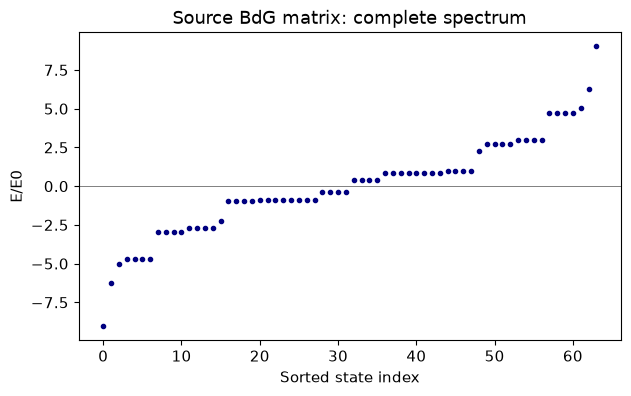

In [4]:
energies, vectors = eigh(h_source)
residual = np.linalg.norm(h_source @ vectors-vectors*energies) / max(1, np.linalg.norm(h_source))
normalization = np.max(abs(vectors.conj().T @ vectors-np.eye(4*n)))
pairing_error = np.max(abs(energies+energies[::-1]))
print(f"Relative eigen-equation residual: {residual:.3e}")
print(f"Orthonormality residual: {normalization:.3e}")
print(f"Energy-pair residual [E0]: {pairing_error:.3e}")
fig, ax = plt.subplots()
ax.plot(np.arange(len(energies)), energies, ".", color="navy")
ax.axhline(0, color="gray", linewidth=0.7)
ax.set(xlabel="Sorted state index", ylabel="E/E0", title="Source BdG matrix: complete spectrum")
plt.show()

## 5. Limiting case: an isolated paired site

With no hopping and $h=-\mu I_2$, a $2\times2$ sub-block is
$$B=\begin{pmatrix}-\mu&\Delta\\\Delta^*&\mu\end{pmatrix}.$$
Its characteristic equation is
$$\det(B-EI)=(-\mu-E)(\mu-E)-|\Delta|^2=E^2-\mu^2-|\Delta|^2=0,$$
so $E=\pm\sqrt{\mu^2+|\Delta|^2}$, each twice in the full spinful matrix. Both terms under the square root have units of energy squared. As $\Delta\to0$, the energies become $\pm|\mu|$; at $\mu=0$, they become $\pm|\Delta|$.

In [5]:
mu_atomic, delta_atomic = 0.3, 0.2
atomic = canonical_bdg(-mu_atomic*np.eye(2), np.array([delta_atomic]))
expected = np.sqrt(mu_atomic**2+delta_atomic**2)*np.array([-1, -1, 1, 1])
print("Atomic energies:", eigh(atomic, eigvals_only=True))
assert np.allclose(eigh(atomic, eigvals_only=True), expected)

Atomic energies: [-0.36055513 -0.36055513  0.36055513  0.36055513]
